In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:


from pathlib import Path

data_dir = Path(r"C:\Users\Asus\Downloads\sentiment+labelled+sentences\sentiment labelled sentences")

amazon = pd.read_csv(
    data_dir / "amazon_cells_labelled.txt",
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

imdb = pd.read_csv(
    data_dir / "imdb_labelled.txt",
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)

yelp = pd.read_csv(
    data_dir / "yelp_labelled.txt",
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)


df = pd.concat([amazon, imdb, yelp], ignore_index=True)


print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Dataset Shape: (2748, 2)


,review,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1
5,I have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,0
7,If you are Razr owner...you must have this!,1
8,"Needless to say, I wasted my money.",0
9,What a waste of money and time!.,0


In [4]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current Working Directory:
c:\Users\Asus\OneDrive\Desktop\datheon task 4

Files available:
['.venv', 'nlp_sentiment_classification.ipynb']


In [7]:
print(df.info())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     2748 non-null   object
 1   sentiment  2748 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 43.1+ KB
None

Sentiment Distribution:
sentiment
1    1386
0    1362
Name: count, dtype: int64


In [10]:

amazon = pd.read_csv(
    "amazon_cells_labelled.txt",
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)


imdb = pd.read_csv(
    "imdb_labelled.txt",
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)


yelp = pd.read_csv(
    "yelp_labelled.txt",
    sep="\t",
    header=None,
    names=["review", "sentiment"]
)


df = pd.concat([amazon, imdb, yelp], ignore_index=True)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Dataset Shape: (2748, 2)


,review,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1
5,I have to jiggle the plug to get it to line up...,0
6,If you have several dozen or several hundred c...,0
7,If you are Razr owner...you must have this!,1
8,"Needless to say, I wasted my money.",0
9,What a waste of money and time!.,0


In [11]:
import os

print(os.listdir())

['.venv', 'amazon_cells_labelled.txt', 'imdb_labelled.txt', 'nlp_sentiment_classification.ipynb', 'sentiment_reviews.csv', 'yelp_labelled.txt']


In [12]:
amazon = pd.read_csv("amazon_cells_labelled.txt", sep="\t",
                     header=None, names=["review", "sentiment"])

imdb = pd.read_csv("imdb_labelled.txt", sep="\t",
                   header=None, names=["review", "sentiment"])

yelp = pd.read_csv("yelp_labelled.txt", sep="\t",
                   header=None, names=["review", "sentiment"])

df = pd.concat([amazon, imdb, yelp], ignore_index=True)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (2748, 2)


,review,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [13]:

print("Total Reviews:", len(df))

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Reviews:", df.duplicated().sum())

Total Reviews: 2748

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     2748 non-null   object
 1   sentiment  2748 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 43.1+ KB

Missing Values:
review       0
sentiment    0
dtype: int64

Duplicate Reviews: 17


In [14]:
print("Sentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nSentiment Labels:")
print("0 = Negative")
print("1 = Positive")

Sentiment Distribution:
sentiment
1    1386
0    1362
Name: count, dtype: int64

Sentiment Labels:
0 = Negative
1 = Positive


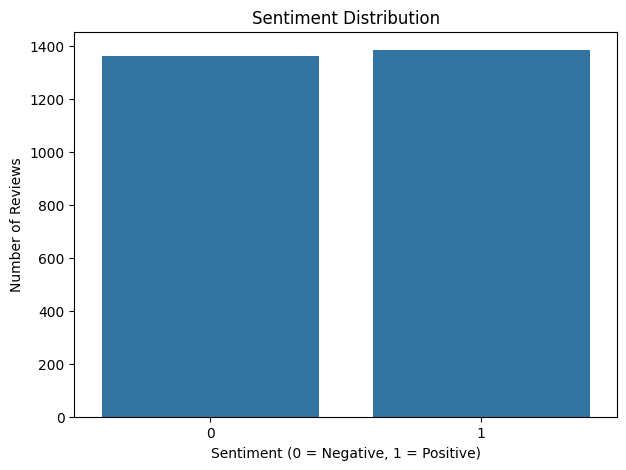

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Reviews")

plt.show()

In [16]:
print("Positive Reviews:")
display(df[df["sentiment"] == 1]["review"].head(5))

print("\nNegative Reviews:")
display(df[df["sentiment"] == 0]["review"].head(5))

Positive Reviews:


1                     Good case, Excellent value.
2                          Great for the jawbone.
4                               The mic is great.
7     If you are Razr owner...you must have this!
10                And the sound quality is great.
Name: review, dtype: object


Negative Reviews:


0    So there is no way for me to plug it in here i...
3    Tied to charger for conversations lasting more...
5    I have to jiggle the plug to get it to line up...
6    If you have several dozen or several hundred c...
8                  Needless to say, I wasted my money.
Name: review, dtype: object

In [17]:


import re

def clean_text(text):

    text = text.lower()

    text = re.sub(r'[^a-zA-Z\s]', '', text)

    
    text = re.sub(r'\s+', ' ', text).strip()

    return text


df["cleaned_review"] = df["review"].apply(clean_text)

print("Text cleaning completed successfully!")

display(df[["review", "cleaned_review"]].head(10))

Text cleaning completed successfully!


,review,cleaned_review
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owneryou must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


In [18]:
for i in range(5):
    print("Original Review:", df["review"].iloc[i])
    print("Cleaned Review:", df["cleaned_review"].iloc[i])
    print("-" * 60)

Original Review: So there is no way for me to plug it in here in the US unless I go by a converter.
Cleaned Review: so there is no way for me to plug it in here in the us unless i go by a converter
------------------------------------------------------------
Original Review: Good case, Excellent value.
Cleaned Review: good case excellent value
------------------------------------------------------------
Original Review: Great for the jawbone.
Cleaned Review: great for the jawbone
------------------------------------------------------------
Original Review: Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
Cleaned Review: tied to charger for conversations lasting more than minutesmajor problems
------------------------------------------------------------
Original Review: The mic is great.
Cleaned Review: the mic is great
------------------------------------------------------------


In [19]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df["cleaned_review"].isnull().sum())

print("\nSample Cleaned Reviews:")
display(df["cleaned_review"].head())

Dataset Shape: (2748, 3)

Missing Values:
0

Sample Cleaned Reviews:


0    so there is no way for me to plug it in here i...
1                            good case excellent value
2                                great for the jawbone
3    tied to charger for conversations lasting more...
4                                     the mic is great
Name: cleaned_review, dtype: object

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)


X = tfidf.fit_transform(df["cleaned_review"])

y = df["sentiment"]

print("TF-IDF Vectorization Completed!")
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)

TF-IDF Vectorization Completed!
Feature Matrix Shape: (2748, 5000)
Target Shape: (2748,)


In [21]:

tfidf_df = pd.DataFrame(
    X.toarray(),
    columns=tfidf.get_feature_names_out()
)

display(tfidf_df.head())

,abandoned,abhor,ability,able,abound,about,above,abovepretty,abroad,absolute,...,youve,yucky,yukon,yum,yummy,yun,za,zero,zillion,zombie
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data Splitting Completed!")

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Data Splitting Completed!
Training Data: (2198, 5000)
Testing Data: (550, 5000)


In [23]:
from sklearn.naive_bayes import MultinomialNB


nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

print("Multinomial Naive Bayes Model Trained Successfully!")

Multinomial Naive Bayes Model Trained Successfully!


In [24]:

nb_predictions = nb_model.predict(X_test)

print("Predictions Completed!")

print("First 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(nb_predictions[:10])

Predictions Completed!
First 10 Actual Values:
[0 0 0 1 1 0 1 1 1 1]

First 10 Predicted Values:
[0 1 0 1 1 0 1 1 1 1]


In [25]:
from sklearn.metrics import accuracy_score, classification_report

nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Model Accuracy:",
      round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=["Negative", "Positive"]
))

Naive Bayes Model Accuracy: 82.91 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.81      0.85      0.83       273
    Positive       0.85      0.81      0.83       277

    accuracy                           0.83       550
   macro avg       0.83      0.83      0.83       550
weighted avg       0.83      0.83      0.83       550



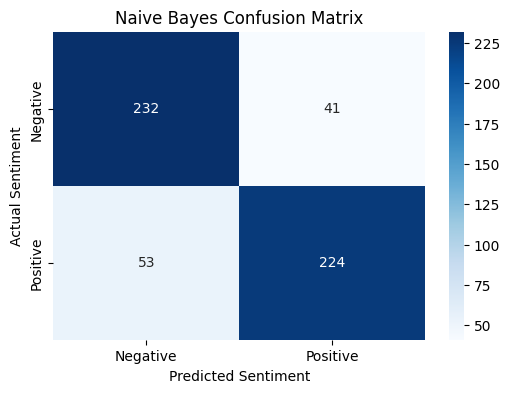

In [26]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, nb_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [27]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [28]:

lr_predictions = lr_model.predict(X_test)

print("Predictions Completed!")

print("First 10 Actual Values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 Predicted Values:")
print(lr_predictions[:10])

Predictions Completed!
First 10 Actual Values:
[0 0 0 1 1 0 1 1 1 1]

First 10 Predicted Values:
[0 1 0 1 1 0 1 1 0 0]


In [29]:
from sklearn.metrics import accuracy_score, classification_report

lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Negative", "Positive"]
))

Logistic Regression Accuracy: 80.91 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.84      0.81       273
    Positive       0.83      0.78      0.80       277

    accuracy                           0.81       550
   macro avg       0.81      0.81      0.81       550
weighted avg       0.81      0.81      0.81       550



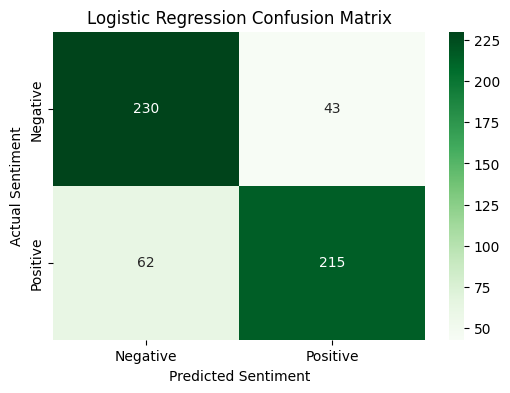

In [30]:
cm_lr = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [31]:
model_comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    "Accuracy": [
        nb_accuracy * 100,
        lr_accuracy * 100
    ]
})

print("Model Performance Comparison:")
display(model_comparison)

Model Performance Comparison:


,Model,Accuracy
0,Naive Bayes,82.909091
1,Logistic Regression,80.909091


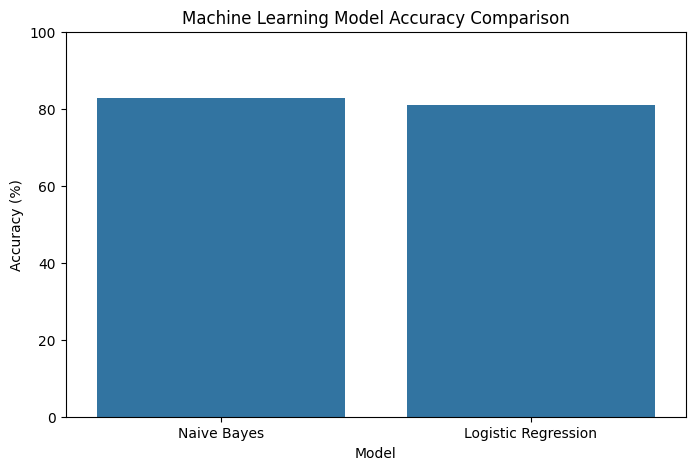

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()

In [33]:

if lr_accuracy >= nb_accuracy:
    best_model = lr_model
    best_model_name = "Logistic Regression"
else:
    best_model = nb_model
    best_model_name = "Naive Bayes"

print("Best Performing Model:", best_model_name)

Best Performing Model: Naive Bayes


In [34]:
def predict_sentiment(review):

    cleaned = clean_text(review)

    review_vector = tfidf.transform([cleaned])

    prediction = best_model.predict(review_vector)[0]

    if prediction == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"

In [35]:
sample_reviews = [
    "This product is absolutely amazing!",
    "The service was very disappointing.",
    "I really enjoyed this experience.",
    "The quality is terrible and I hate it."
]

for review in sample_reviews:

    result = predict_sentiment(review)

    print("Review:", review)
    print("Predicted Sentiment:", result)
    print("-" * 60)

Review: This product is absolutely amazing!
Predicted Sentiment: Positive 😊
------------------------------------------------------------
Review: The service was very disappointing.
Predicted Sentiment: Negative 😞
------------------------------------------------------------
Review: I really enjoyed this experience.
Predicted Sentiment: Positive 😊
------------------------------------------------------------
Review: The quality is terrible and I hate it.
Predicted Sentiment: Negative 😞
------------------------------------------------------------


In [3]:
user_review = "This product is absolutely amazing and I love it!"

result = predict_sentiment(user_review)

print("Customer Review:", user_review)
print("Sentiment Prediction:", result)

NameError: name 'predict_sentiment' is not defined

In [9]:
import os

print("Notebook location:", os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Notebook location: c:\Users\Asus\OneDrive\Desktop\datheon task 4

Files in current folder:
['.venv', 'nlp_sentiment_classification.ipynb', 'sentiment_reviews.csv']


In [2]:
print("Python kernel is working!")

Python kernel is working!


In [4]:
def predict_sentiment(review):

   
    cleaned = clean_text(review)

    review_vector = tfidf.transform([cleaned])

    prediction = best_model.predict(review_vector)[0]

    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

print("Prediction function created successfully!")

Prediction function created successfully!


In [5]:
user_review = "This product is absolutely amazing and I love it!"

result = predict_sentiment(user_review)

print("Customer Review:", user_review)
print("Sentiment Prediction:", result)

NameError: name 'clean_text' is not defined

In [6]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("Text cleaning function restored!")

Text cleaning function restored!


In [7]:
print("TF-IDF available:", 'tfidf' in globals())
print("Best model available:", 'best_model' in globals())

TF-IDF available: False
Best model available: False


In [8]:
import os

print("Current folder:", os.getcwd())

print("\nAvailable files:")
print(os.listdir())

Current folder: c:\Users\Asus\OneDrive\Desktop\datheon task 4

Available files:
['.venv', 'amazon_cells_labelled.txt', 'imdb_labelled.txt', 'nlp_sentiment_classification.ipynb', 'sentiment_reviews.csv', 'yelp_labelled.txt']


In [9]:
import pandas as pd
import numpy as np
import re
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


amazon = pd.read_csv("amazon_cells_labelled.txt", sep="\t", header=None,
                     names=["review", "sentiment"])

imdb = pd.read_csv("imdb_labelled.txt", sep="\t", header=None,
                   names=["review", "sentiment"])

yelp = pd.read_csv("yelp_labelled.txt", sep="\t", header=None,
                   names=["review", "sentiment"])


df = pd.concat([amazon, imdb, yelp], ignore_index=True)


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["cleaned_review"] = df["review"].apply(clean_text)

tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df["cleaned_review"])
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset and TF-IDF restored successfully!")
print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)

Dataset and TF-IDF restored successfully!
Dataset shape: (2748, 3)
Feature shape: (2748, 5000)


In [10]:

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

nb_predictions = nb_model.predict(X_test)
nb_accuracy = accuracy_score(y_test, nb_predictions)


lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 82.91 %
Logistic Regression Accuracy: 80.91 %


In [11]:
if lr_accuracy >= nb_accuracy:
    best_model = lr_model
    best_model_name = "Logistic Regression"
else:
    best_model = nb_model
    best_model_name = "Naive Bayes"

joblib.dump(best_model, "sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Best Model:", best_model_name)
print("Model saved successfully!")

Best Model: Naive Bayes
Model saved successfully!


In [12]:
def predict_sentiment(review):
    cleaned = clean_text(review)
    review_vector = tfidf.transform([cleaned])
    prediction = best_model.predict(review_vector)[0]

    return "Positive" if prediction == 1 else "Negative"

user_review = "This product is absolutely amazing and I love it!"

print("Customer Review:", user_review)
print("Sentiment Prediction:", predict_sentiment(user_review))

Customer Review: This product is absolutely amazing and I love it!
Sentiment Prediction: Positive
